# Análisis exploratorio — Detección de fraude (Caso 1)

**Objetivo:** entender el dataset de transacciones y dejarlo listo para entrenar modelos que predigan `fraud`, controlando el desbalance y evitando fuga de información.

**Contenido**
0. Configuración del entorno
1. Carga y estructura
2. Calidad de datos
3. Variable objetivo
4. Variables numéricas
5. Variables categóricas
6. Correlación y redundancia
7. Selección de variables
8. División train/test
9. Codificación One-Hot
10. Conclusiones

## 0. Configuración del entorno

Se instala PyTorch con soporte CUDA 13 para la RTX 5070.

In [1]:
%pip install -q --disable-pip-version-check torch --index-url https://download.pytorch.org/whl/cu130

Note: you may need to restart the kernel to use updated packages.


Se instalan las librerías de análisis, gráficas y modelado.

In [2]:
%pip install -q --disable-pip-version-check pandas numpy matplotlib seaborn scipy scikit-learn skorch

Note: you may need to restart the kernel to use updated packages.


Se verifica que PyTorch detecte la GPU.

In [3]:
import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna"
print(f"torch {torch.__version__} | CUDA: {torch.cuda.is_available()} | GPU: {gpu}")

torch 2.14.1+cu130 | CUDA: True | GPU: NVIDIA GeForce RTX 5070


Se importan las librerías, se fija el estilo de las gráficas y se definen los grupos de columnas.

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter, PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

RUTA = Path("data/transacciones_fraude_bigdata.csv")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

ID, TARGET = ["transaction_id", "customer_id"], "fraud"
NUM_CONT = ["amount_usd", "avg_amount_30d", "amount_vs_avg", "distance_home_km", "ip_risk_score"]
NUM_DISC = ["hour", "day_of_week", "transactions_24h", "account_age_days", "failed_attempts_24h"]
CAT = ["channel", "merchant_category", "country", "device_type"]
BIN = ["is_international", "card_present", "new_device"]
NUM = NUM_CONT + NUM_DISC

## 1. Carga y estructura (paso 1)

Se carga el dataset y se muestran sus dimensiones y memoria.

In [5]:
df = pd.read_csv(RUTA)
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas | Memoria: {df.memory_usage(deep=True).sum()/1e6:.2f} MB")

Dimensiones: 50,000 filas x 20 columnas | Memoria: 22.45 MB


Se revisa el tipo de dato y los no nulos de cada columna.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       50000 non-null  str    
 1   customer_id          50000 non-null  str    
 2   amount_usd           50000 non-null  float64
 3   hour                 50000 non-null  int64  
 4   day_of_week          50000 non-null  int64  
 5   channel              50000 non-null  str    
 6   merchant_category    50000 non-null  str    
 7   country              50000 non-null  str    
 8   device_type          50000 non-null  str    
 9   is_international     50000 non-null  int64  
 10  card_present         50000 non-null  int64  
 11  transactions_24h     50000 non-null  int64  
 12  avg_amount_30d       50000 non-null  float64
 13  amount_vs_avg        50000 non-null  float64
 14  distance_home_km     50000 non-null  float64
 15  account_age_days     50000 non-null  int64  
 1

Se muestran las primeras filas para ver el formato de los datos.

In [7]:
df.head()

,transaction_id,customer_id,amount_usd,hour,day_of_week,channel,merchant_category,country,device_type,is_international,card_present,transactions_24h,avg_amount_30d,amount_vs_avg,distance_home_km,account_age_days,failed_attempts_24h,new_device,ip_risk_score,fraud
0,TX20260907000001,C008517,10.020,11,6,WEB,servicios,US,terminal,1,0,3,18.730,0.535,9.230,4917,1,0,9.100,0
1,TX20260907000002,C002445,6.430,10,2,WEB,otros,EC,movil,0,0,4,26.790,0.240,22.250,666,0,0,14.700,0
2,TX20260907000003,C001658,161.910,13,0,WEB,viajes,EC,terminal,0,0,3,25.870,6.259,21.550,4952,0,0,12.000,0
3,TX20260907000004,C005925,769.080,6,3,POS,servicios,EC,cajero,0,1,7,38.130,20.170,7.610,2917,0,0,24.600,0
4,TX20260907000005,C007619,248.590,17,1,POS,alimentos,EC,movil,0,1,2,21.850,11.377,3.390,1489,1,0,24.200,0


Se cuentan los valores únicos por columna para confirmar la cardinalidad de cada variable.

In [8]:
pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unicos": df.nunique()})

,dtype,n_unicos
transaction_id,str,50000
customer_id,str,11821
amount_usd,float64,20823
hour,int64,24
day_of_week,int64,7
channel,str,4
merchant_category,str,8
country,str,7
device_type,str,5
is_international,int64,2


## 2. Calidad de datos (paso 1)

Se verifican duplicados y faltantes en todo el dataset.

In [9]:
print(f"Filas duplicadas: {df.duplicated().sum()} | transaction_id repetidos: {df['transaction_id'].duplicated().sum()} "
      f"| Celdas faltantes: {int(df.isna().sum().sum())}")

Filas duplicadas: 0 | transaction_id repetidos: 0 | Celdas faltantes: 0


Se detallan los faltantes por columna.

In [10]:
pd.DataFrame({"n_faltantes": df.isna().sum(), "%": df.isna().mean() * 100})

,n_faltantes,%
transaction_id,0,0.000
customer_id,0,0.000
amount_usd,0,0.000
hour,0,0.000
day_of_week,0,0.000
channel,0,0.000
merchant_category,0,0.000
country,0,0.000
device_type,0,0.000
is_international,0,0.000


Se verifica que las categorías no tengan variantes de escritura (mayúsculas, espacios o tildes).

In [11]:
norm = lambda s: s.str.strip().str.lower().str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
pd.DataFrame({c: {"valores": sorted(df[c].unique()),
                  "n_unicos": df[c].nunique(),
                  "n_unicos_normalizado": norm(df[c]).nunique()} for c in CAT}).T

,valores,n_unicos,n_unicos_normalizado
channel,"[APP, ATM, POS, WEB]",4,4
merchant_category,"[alimentos, entretenimiento, otros, retail, se...",8,8
country,"[CO, EC, ES, MX, OTRO, PE, US]",7,7
device_type,"[cajero, desktop, movil, tablet, terminal]",5,5


## 3. Variable objetivo (paso 2)

Se cuantifica la distribución de la variable objetivo.

In [12]:
pd.DataFrame({"n": df[TARGET].value_counts(), "%": df[TARGET].value_counts(normalize=True) * 100})

,n,%
fraud,,
0,49091,98.182
1,909,1.818


Se grafica el desbalance entre transacciones legítimas y fraudulentas.

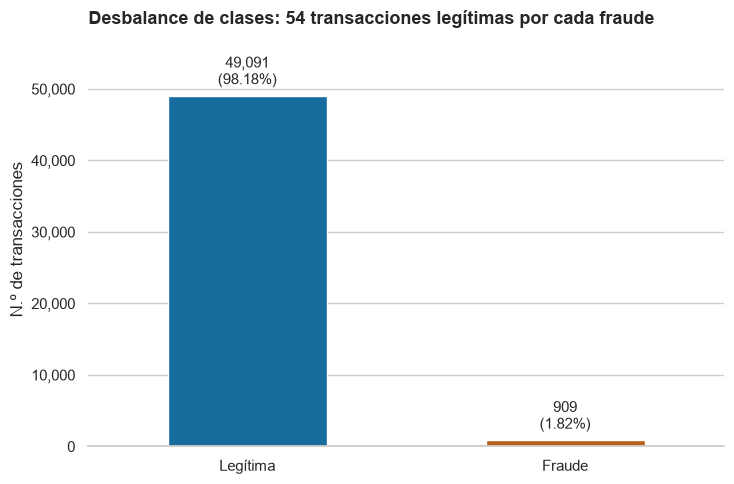

In [13]:
# Azul / naranja-bermellón (Okabe-Ito): se distinguen incluso con daltonismo
COLORES = {"Legítima": "#0072B2", "Fraude": "#D55E00"}

cnt = df[TARGET].map({0: "Legítima", 1: "Fraude"}).value_counts().reindex(COLORES)
ratio = cnt["Legítima"] / cnt["Fraude"]

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.barplot(x=cnt.index, y=cnt.values, hue=cnt.index, palette=COLORES,
            dodge=False, width=0.5, legend=False, ax=ax)

# Etiqueta directa sobre cada barra: conteo y porcentaje
for p in ax.patches:
    h = p.get_height()
    if h <= 0:
        continue
    ax.annotate(f"{h:,.0f}\n({h/len(df)*100:.2f}%)",
                (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom", xytext=(0, 5),
                textcoords="offset points", fontsize=11)

ax.set_ylim(0, cnt.max() * 1.18)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("")
ax.set_ylabel("N.º de transacciones")
ax.grid(axis="x", visible=False)
ax.set_title(f"Desbalance de clases: {ratio:.0f} transacciones legítimas por cada fraude",
             loc="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
guardar("02_target")

## 4. Variables numéricas (paso 2)

### 4.1 Estadísticas descriptivas

Se calculan medidas de tendencia central, dispersión y forma de las variables numéricas.

In [14]:
res = pd.DataFrame({
    "min": df[NUM].min(), "max": df[NUM].max(),
    "rango": df[NUM].max() - df[NUM].min(),
    "media": df[NUM].mean(), "mediana": df[NUM].median(), "moda": df[NUM].mode().iloc[0],
    "std": df[NUM].std(), "asimetria": df[NUM].skew(), "curtosis": df[NUM].kurt(),
})
res["media/mediana"] = res["media"] / res["mediana"]
res

,min,max,rango,media,mediana,moda,std,asimetria,curtosis,media/mediana
amount_usd,0.500,"5,000.000","4,999.500",106.520,54.600,22.320,171.941,6.808,89.627,1.951
avg_amount_30d,1.000,"2,197.550","2,196.550",61.547,44.530,23.440,59.927,4.825,69.038,1.382
amount_vs_avg,0.004,506.127,506.123,3.294,1.238,0.150,8.174,16.668,606.233,2.661
distance_home_km,0.050,173.980,173.930,23.989,20.120,13.270,16.935,1.420,2.990,1.192
ip_risk_score,0.000,88.000,88.000,23.627,21.100,12.300,14.868,0.771,0.199,1.120
hour,0.000,23.000,23.000,11.507,11.000,11.000,6.919,0.006,-1.202,1.046
day_of_week,0.000,6.000,6.000,2.996,3.000,1.000,2.001,0.006,-1.251,0.999
transactions_24h,1.000,15.000,14.000,4.192,4.000,4.000,1.786,0.568,0.359,1.048
account_age_days,5.000,"4,999.000","4,994.000","2,499.312","2,499.000","4,334.000","1,446.173",0.004,-1.206,1.000
failed_attempts_24h,0.000,4.000,4.000,0.250,0.000,0.000,0.498,1.984,3.924,inf


### 4.2 Outliers

Se grafica un boxplot por variable numérica para identificar outliers.

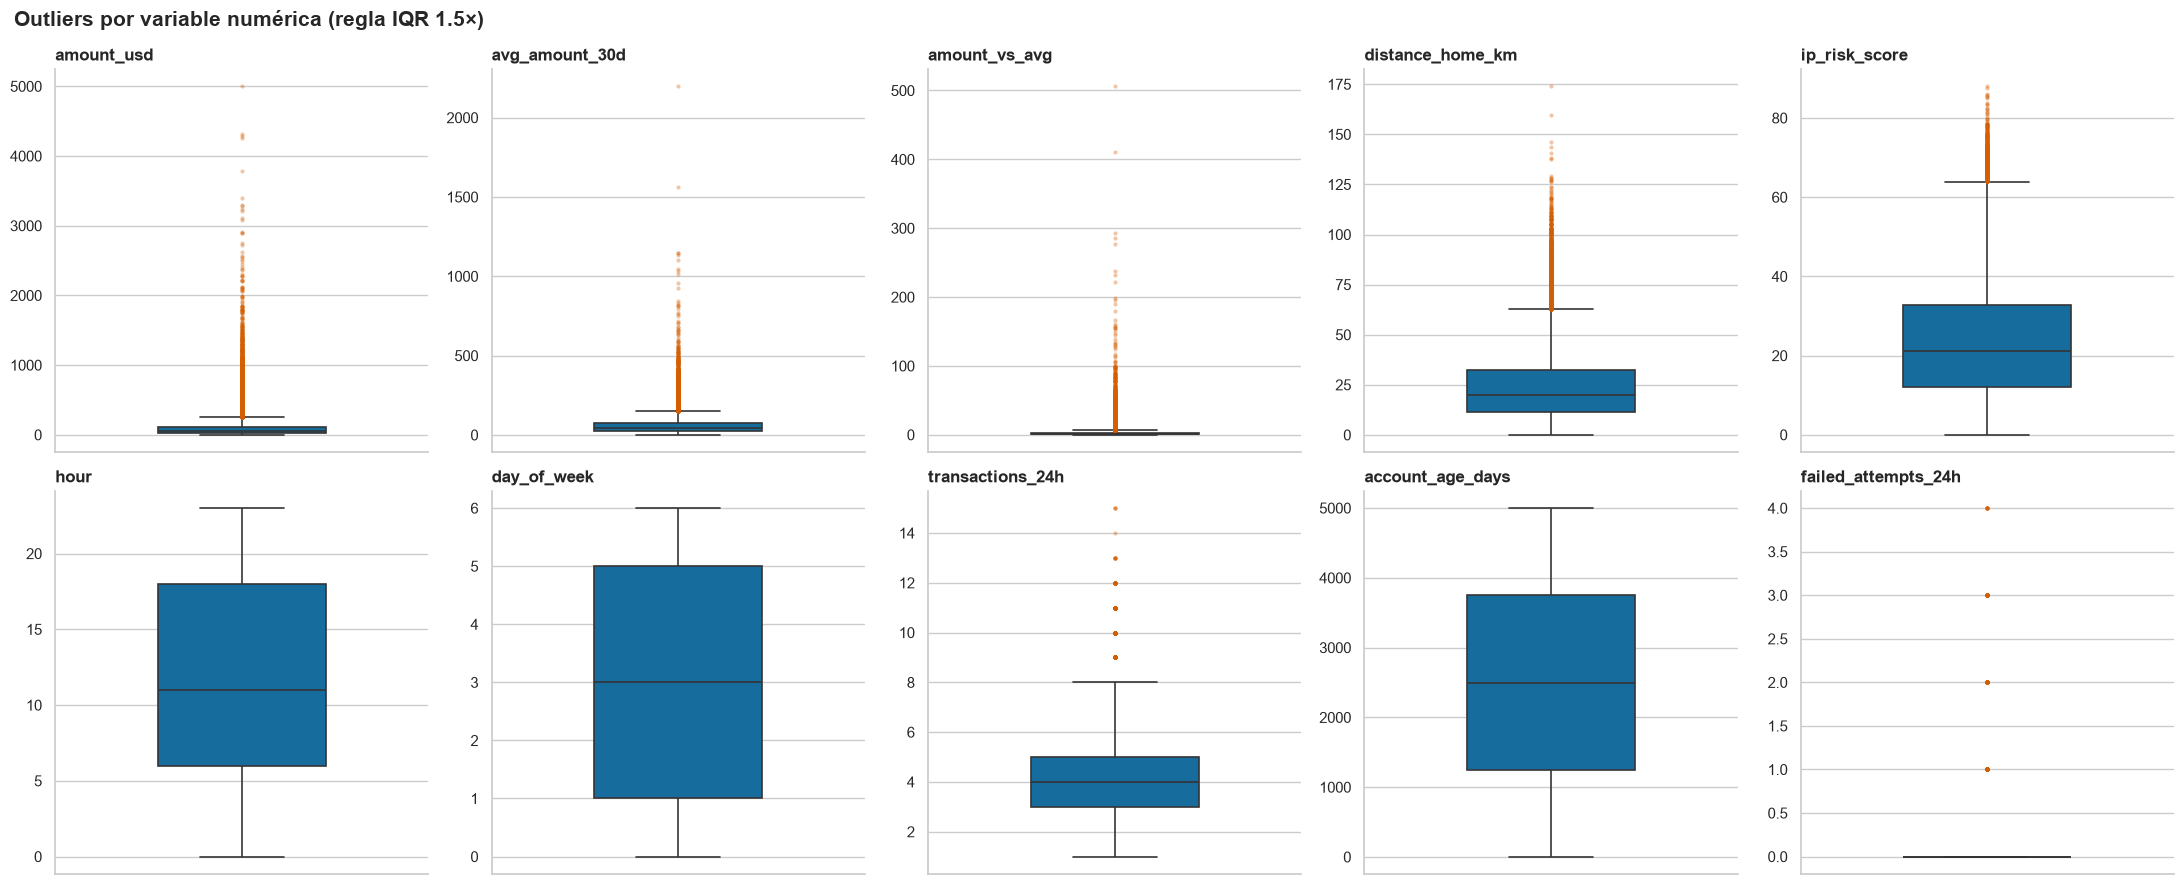

In [15]:
COLOR = "#0072B2"
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, c in zip(axes.ravel(), NUM):
    sns.boxplot(y=df[c], ax=ax, color=COLOR, width=0.45, linewidth=1.2,
                flierprops=dict(marker="o", markersize=3, alpha=0.35,
                                markerfacecolor="#D55E00", markeredgecolor="none"))
    ax.set_title(c, loc="left", fontweight="bold")
    ax.set_ylabel("")
fig.suptitle("Outliers por variable numérica (regla IQR 1.5×)", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
sns.despine()
guardar("05_boxplots")

Se cuantifican los outliers por variable con la regla IQR 1.5×.

In [16]:
def iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    n = ((s < lo) | (s > hi)).sum()
    return pd.Series({"lim_inf": lo, "lim_sup": hi, "n_outliers": n, "%": n / len(s) * 100})

df[NUM].apply(iqr).T.sort_values("%", ascending=False)

,lim_inf,lim_sup,n_outliers,%
failed_attempts_24h,0.000,0.000,"11,098.000",22.196
amount_vs_avg,-3.540,7.180,"5,238.000",10.476
amount_usd,-114.584,258.466,"4,570.000",9.140
avg_amount_30d,-50.495,153.145,"3,100.000",6.200
distance_home_km,-19.170,62.910,"1,632.000",3.264
transactions_24h,0.000,8.000,814.000,1.628
ip_risk_score,-19.200,64.000,581.000,1.162
hour,-12.000,36.000,0.000,0.000
day_of_week,-5.000,11.000,0.000,0.000
account_age_days,"-2,532.500","7,527.500",0.000,0.000


Se compara la tasa de fraude dentro y fuera de los outliers de cada variable.

In [17]:
def mask_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

filas = []
for c in NUM:
    m = mask_iqr(df[c])
    if m.sum() == 0:
        continue
    filas.append({"variable": c,
                  "n_outliers": m.sum(),
                  "% fraude en outliers": df.loc[m, TARGET].mean() * 100,
                  "% fraude en resto": df.loc[~m, TARGET].mean() * 100,
                  "fraudes que se perderían": df.loc[m, TARGET].sum()})
tabla = pd.DataFrame(filas).set_index("variable").sort_values("% fraude en outliers", ascending=False)
tabla

,n_outliers,% fraude en outliers,% fraude en resto,fraudes que se perderían
variable,,,,
transactions_24h,814,4.423,1.775,36
amount_usd,4570,3.611,1.638,165
amount_vs_avg,5238,3.322,1.642,174
ip_risk_score,581,2.238,1.813,13
failed_attempts_24h,11098,1.946,1.781,216
avg_amount_30d,3100,1.677,1.827,52
distance_home_km,1632,1.287,1.836,21


Se estima cuántos fraudes se perderían si se eliminaran todas las filas con algún outlier.

In [18]:
m_any = pd.concat([mask_iqr(df[c]) for c in NUM], axis=1).any(axis=1)
perdidos = df.loc[m_any, TARGET].sum()
print(f"Eliminar filas con algún outlier: se pierden {m_any.sum():,} filas ({m_any.mean()*100:.1f}%) "
      f"y {perdidos} de {df[TARGET].sum()} fraudes ({perdidos/df[TARGET].sum()*100:.1f}%)")

Eliminar filas con algún outlier: se pierden 20,538 filas (41.1%) y 447 de 909 fraudes (49.2%)


Se grafica la tasa de fraude en outliers frente al resto.

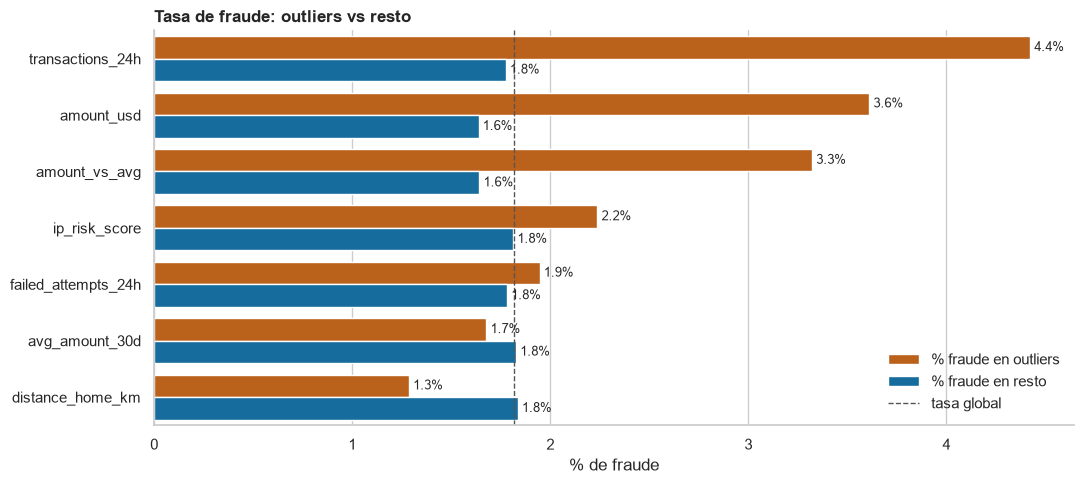

In [19]:
plot_df = (tabla[["% fraude en outliers", "% fraude en resto"]].reset_index()
           .melt(id_vars="variable", var_name="grupo", value_name="% fraude"))
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, y="variable", x="% fraude", hue="grupo",
            palette={"% fraude en outliers": "#D55E00", "% fraude en resto": "#0072B2"}, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", padding=3, fontsize=9)
ax.axvline(df[TARGET].mean() * 100, color="#555", ls="--", lw=1, label="tasa global")
ax.set(xlabel="% de fraude", ylabel="")
ax.set_title("Tasa de fraude: outliers vs resto", loc="left", fontweight="bold")
ax.legend(title=None, frameon=False)
sns.despine()
guardar("06_outliers_vs_fraude")

### 4.3 Escala y asimetría

Se asigna a cada variable la transformación recomendada según su asimetría y el tipo de modelo.

In [20]:
def recomendar(c):
    r = res.loc[c]
    if c in NUM_CONT and abs(r["asimetria"]) > 1 and r["min"] >= 0:
        return "log1p + StandardScaler"
    return "StandardScaler"

res["LR y red"] = [recomendar(c) for c in res.index]
res["árboles"] = "sin transformar"
res[["rango", "asimetria", "LR y red", "árboles"]].sort_values("asimetria", key=abs, ascending=False)

,rango,asimetria,LR y red,árboles
amount_vs_avg,506.123,16.668,log1p + StandardScaler,sin transformar
amount_usd,"4,999.500",6.808,log1p + StandardScaler,sin transformar
avg_amount_30d,"2,196.550",4.825,log1p + StandardScaler,sin transformar
failed_attempts_24h,4.000,1.984,StandardScaler,sin transformar
distance_home_km,173.930,1.420,log1p + StandardScaler,sin transformar
ip_risk_score,88.000,0.771,StandardScaler,sin transformar
transactions_24h,14.000,0.568,StandardScaler,sin transformar
hour,23.000,0.006,StandardScaler,sin transformar
day_of_week,6.000,0.006,StandardScaler,sin transformar
account_age_days,"4,994.000",0.004,StandardScaler,sin transformar


Se compara la distribución original y la transformada con log1p de las variables sesgadas.

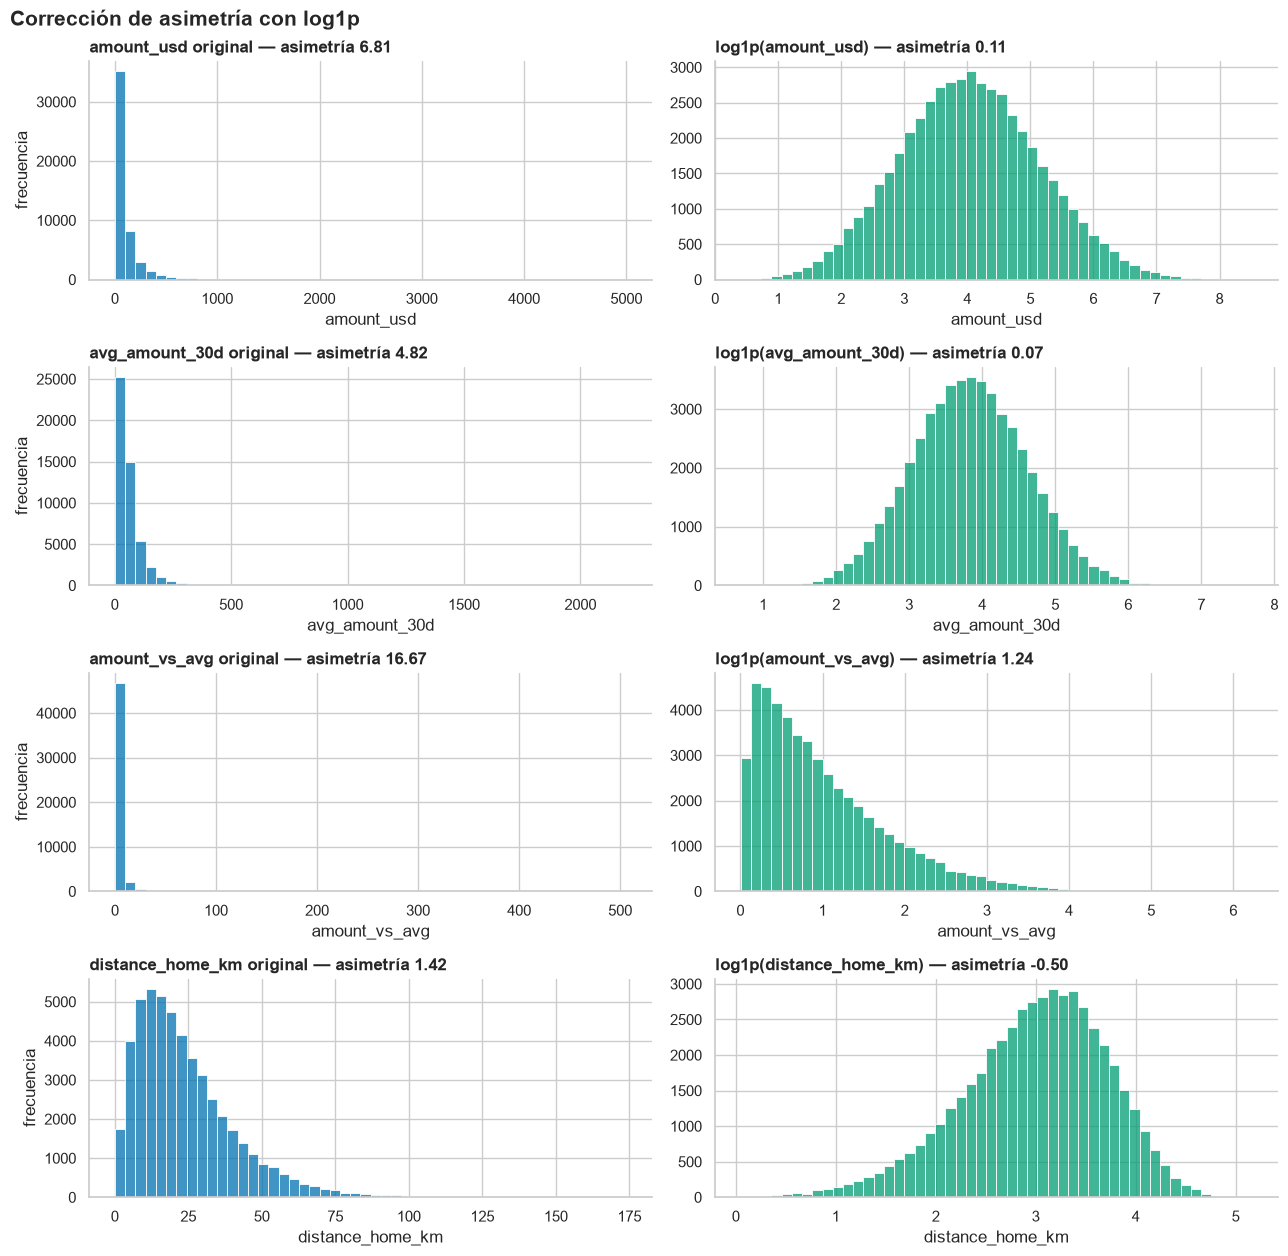

In [21]:
SESGADAS = [c for c in res.index if res.loc[c, "LR y red"].startswith("log1p")]

fig, axes = plt.subplots(len(SESGADAS), 2, figsize=(13, 3.2 * len(SESGADAS)), squeeze=False)
for (a1, a2), c in zip(axes, SESGADAS):
    sns.histplot(df[c], bins=50, ax=a1, color="#0072B2")
    a1.set_title(f"{c} original — asimetría {df[c].skew():.2f}", loc="left", fontweight="bold")
    t = np.log1p(df[c])
    sns.histplot(t, bins=50, ax=a2, color="#009E73")
    a2.set_title(f"log1p({c}) — asimetría {t.skew():.2f}", loc="left", fontweight="bold")
    a1.set_ylabel("frecuencia"); a2.set_ylabel("")
fig.suptitle("Corrección de asimetría con log1p", x=0.01, ha="left", fontsize=15, fontweight="bold")
sns.despine()
guardar("07_normalizacion")

## 5. Variables categóricas (paso 2)

### 5.1 Categorías por variable

Se listan los canales o plataformas (channel) con su frecuencia.

In [22]:
pd.DataFrame({"n": df["channel"].value_counts(), "%": df["channel"].value_counts(normalize=True) * 100})

,n,%
channel,,
POS,20838,41.676
WEB,12557,25.114
APP,12548,25.096
ATM,4057,8.114


Se listan las categorías de comercio (merchant_category) con su frecuencia.

In [23]:
pd.DataFrame({"n": df["merchant_category"].value_counts(), "%": df["merchant_category"].value_counts(normalize=True) * 100})

,n,%
merchant_category,,
alimentos,11115,22.230
retail,9124,18.248
servicios,7589,15.178
transporte,5903,11.806
otros,4853,9.706
entretenimiento,4392,8.784
tecnologia,4052,8.104
viajes,2972,5.944


Se listan los países (country) con su frecuencia.

In [24]:
pd.DataFrame({"n": df["country"].value_counts(), "%": df["country"].value_counts(normalize=True) * 100})

,n,%
country,,
EC,39858,79.716
US,2505,5.010
CO,2032,4.064
PE,1753,3.506
OTRO,1531,3.062
MX,1296,2.592
ES,1025,2.050


Se listan los tipos de dispositivo (device_type) con su frecuencia.

In [25]:
pd.DataFrame({"n": df["device_type"].value_counts(), "%": df["device_type"].value_counts(normalize=True) * 100})

,n,%
device_type,,
movil,19387,38.774
terminal,14106,28.212
desktop,9570,19.140
cajero,3904,7.808
tablet,3033,6.066


### 5.2 Relación con fraud

Se resume la frecuencia y la tasa de fraude de cada categoría de las variables categóricas y binarias.

In [26]:
resumen_cat = pd.concat(
    {c: df.groupby(c)[TARGET].agg(n="size", fraudes="sum", tasa="mean")
          .assign(**{"% del total": lambda t: t["n"] / len(df) * 100, "% fraude": lambda t: t["tasa"] * 100})
          .drop(columns="tasa").sort_values("% fraude", ascending=False)
     for c in CAT + BIN},
    names=["variable", "categoría"])
resumen_cat

n  fraudes  % del total  % fraude
variable          categoría                                             
channel           WEB              12557      299       25.114     2.381
                  APP              12548      298       25.096     2.375
                  ATM               4057       56        8.114     1.380
                  POS              20838      256       41.676     1.229
merchant_category viajes            2972      103        5.944     3.466
                  tecnologia        4052       96        8.104     2.369
                  alimentos        11115      199       22.230     1.790
                  entretenimiento   4392       73        8.784     1.662
                  retail            9124      148       18.248     1.622
                  servicios         7589      123       15.178     1.621
                  transporte        5903       95       11.806     1.609
                  otros             4853       72        9.706     1.484
country           OTRO              1531       59        3.062     3.854
                  MX                1296       47        2.592     3.627
                  CO                2032       70        4.064     3.445
                  PE                1753       56        3.506     3.195
                  US                2505       75        5.010     2.994
                  ES                1025       26        2.050     2.537
                  EC               39858      576       79.716     1.445
device_type       tablet            3033       67        6.066     2.209
                  cajero            3904       79        7.808     2.024
                  desktop           9570      171       19.140     1.787
                  movil            19387      346       38.774     1.785
                  terminal         14106      246       28.212     1.744
is_international  1                10142      333       20.284     3.283
                  0                39858      576       79.716     1.445
card_present      0                25133      606       50.266     2.411
                  1                24867      303       49.734     1.218
new_device        1                 5062      151       10.124     2.983
                  0                44938      758       89.876     1.687

Se grafica la tasa de fraude por categoría con intervalos de confianza del 95%.

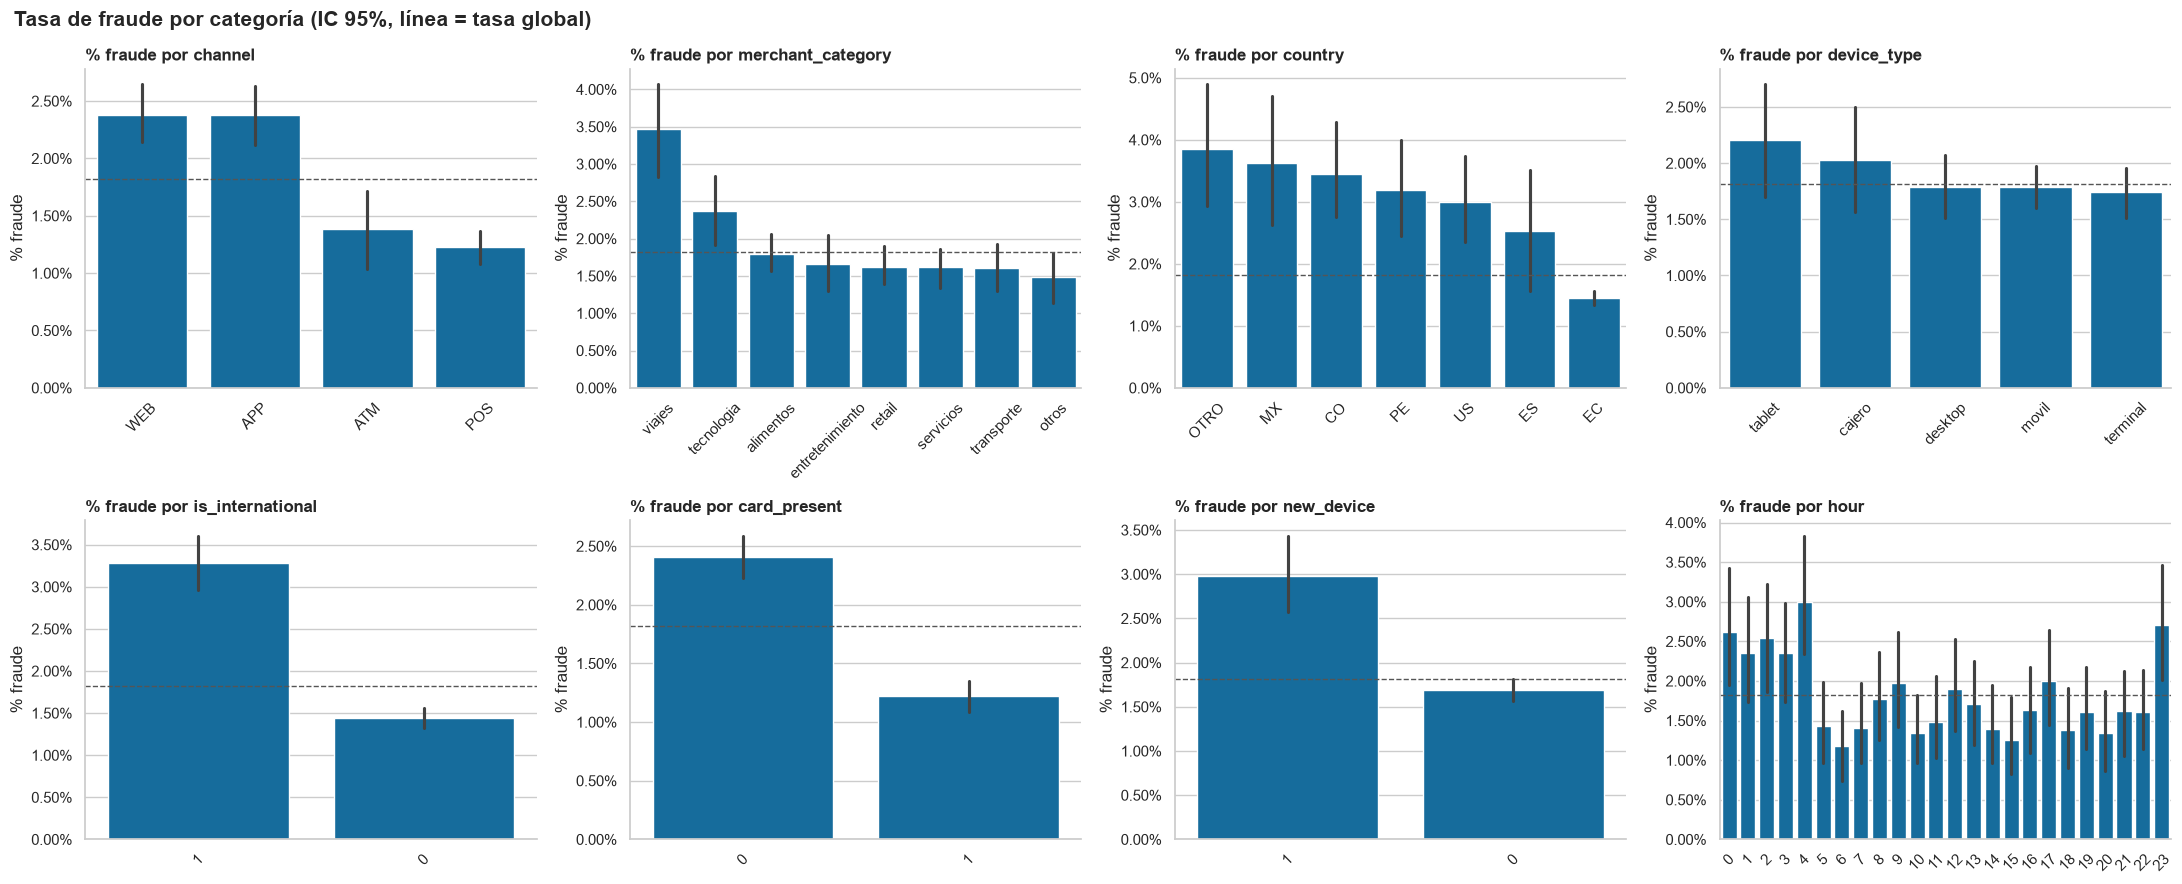

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, c in zip(axes.ravel(), CAT + BIN + ["hour"]):
    orden = None if c == "hour" else df.groupby(c)[TARGET].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x=c, y=TARGET, order=orden, errorbar=("ci", 95), n_boot=500,
                color="#0072B2", ax=ax)
    ax.axhline(df[TARGET].mean(), ls="--", color="#555", lw=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(xlabel="", ylabel="% fraude")
    ax.set_title(f"% fraude por {c}", loc="left", fontweight="bold")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Tasa de fraude por categoría (IC 95%, línea = tasa global)",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
sns.despine()
guardar("08_tasa_fraude_categorias")

### 5.3 Coherencia entre variables

Se verifica la coherencia entre el país y la marca de operación internacional.

In [28]:
pd.crosstab(df["country"], df["is_international"])

is_international,0,1
country,,
CO,0,2032
EC,39858,0
ES,0,1025
MX,0,1296
OTRO,0,1531
PE,0,1753
US,0,2505


Se verifica la coherencia entre el canal y la presencia física de la tarjeta.

In [29]:
pd.crosstab(df["channel"], df["card_present"])

card_present,0,1
channel,,
APP,12192,356
ATM,119,3938
POS,648,20190
WEB,12174,383


Se compara la tasa de fraude según la presencia de la tarjeta dentro de cada canal para verificar si card_present aporta información más allá de channel.

In [30]:
(df.groupby(["channel", "card_present"])[TARGET].agg(n="size", fraudes="sum", tasa="mean")
   .assign(**{"% fraude": lambda t: t["tasa"] * 100}).drop(columns="tasa"))

n  fraudes  % fraude
channel card_present                          
APP     0             12192      295     2.420
        1               356        3     0.843
ATM     0               119        4     3.361
        1              3938       52     1.320
POS     0               648       11     1.698
        1             20190      245     1.213
WEB     0             12174      296     2.431
        1               383        3     0.783

## 6. Correlación y redundancia (paso 3)

Se grafica la matriz de correlación de Spearman entre todas las variables, incluyendo cada categoría como columna One-Hot y la etiqueta fraud en la última fila.

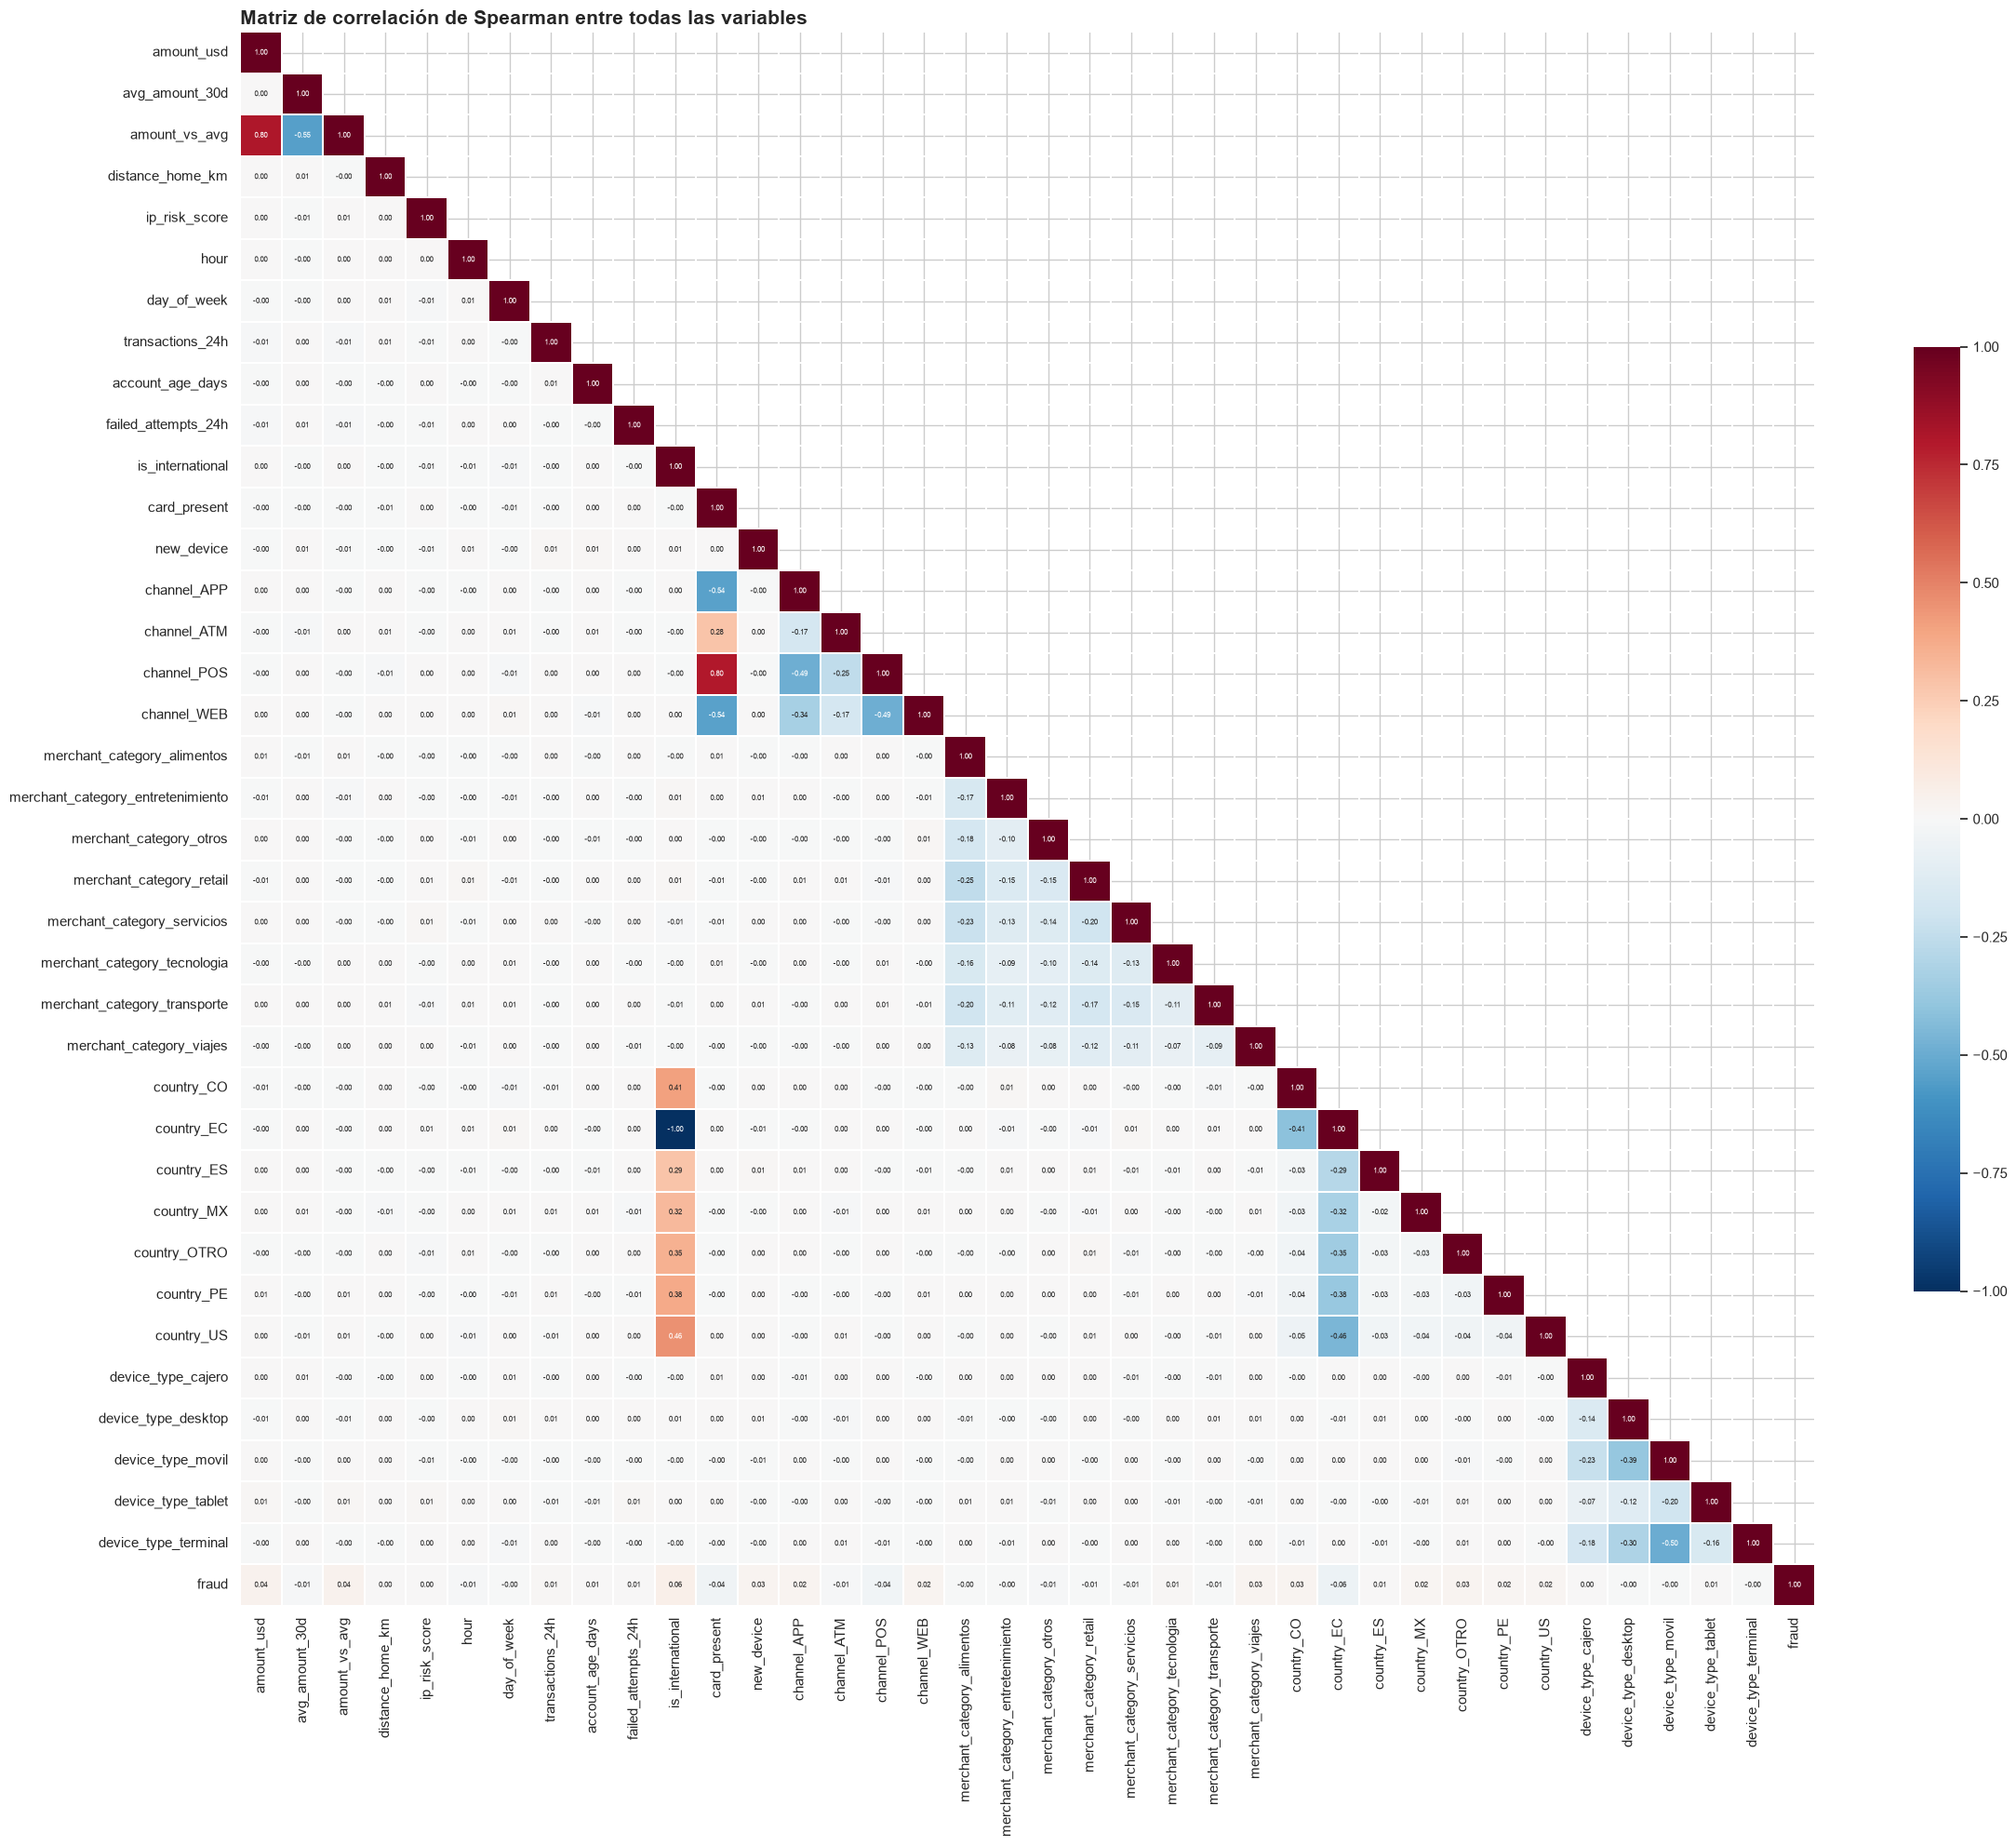

In [31]:
dummies = pd.get_dummies(df[CAT], dtype=int)
corr = pd.concat([df[NUM + BIN], dummies, df[TARGET]], axis=1).corr(method="spearman")
plt.figure(figsize=(24, 20))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            annot_kws={"size": 6}, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.6})
plt.title("Matriz de correlación de Spearman entre todas las variables", loc="left", fontsize=15, fontweight="bold")
guardar("09_correlacion")

Se comprueba si amount_vs_avg es el cociente exacto de amount_usd entre avg_amount_30d.

In [32]:
dif = (df["amount_vs_avg"] - df["amount_usd"] / df["avg_amount_30d"]).abs()
print(f"Diferencia entre amount_vs_avg y amount_usd/avg_amount_30d → máx: {dif.max():.4f} | media: {dif.mean():.5f}")

Diferencia entre amount_vs_avg y amount_usd/avg_amount_30d → máx: 0.0005 | media: 0.00025


## 7. Selección de variables (paso 3)

Se verifica que los identificadores no aportan información predictiva y se decide su tratamiento.

In [33]:
print(f"transaction_id: {df['transaction_id'].nunique():,} valores únicos en {len(df):,} filas (uno por transacción) → sin patrón, solo se conserva para rastrear errores\n"
      f"customer_id: {df['customer_id'].nunique():,} clientes (~{len(df)/df['customer_id'].nunique():.1f} transacciones c/u) → no se usa como predictor directo (paso 3 del PDF) y no se guarda")

transaction_id: 50,000 valores únicos en 50,000 filas (uno por transacción) → sin patrón, solo se conserva para rastrear errores
customer_id: 11,821 clientes (~4.2 transacciones c/u) → no se usa como predictor directo (paso 3 del PDF) y no se guarda


Se excluyen is_international por ser redundante con country y avg_amount_30d por ser derivable de amount_usd / amount_vs_avg, evitando colinealidad.

In [34]:
EXCLUIR = ["is_international", "avg_amount_30d"]
df = df.drop(columns=EXCLUIR)
NUM_CONT = [c for c in NUM_CONT if c not in EXCLUIR]
BIN = [c for c in BIN if c not in EXCLUIR]
NUM = NUM_CONT + NUM_DISC
print(f"Excluidas: {EXCLUIR} | Predictoras restantes ({len(NUM + CAT + BIN)}): {NUM + CAT + BIN}")

Excluidas: ['is_international', 'avg_amount_30d'] | Predictoras restantes (15): ['amount_usd', 'amount_vs_avg', 'distance_home_km', 'ip_risk_score', 'hour', 'day_of_week', 'transactions_24h', 'account_age_days', 'failed_attempts_24h', 'channel', 'merchant_category', 'country', 'device_type', 'card_present', 'new_device']


## 8. División train/test (paso 4)

Se divide el dataset en train (80%) y test (20%) estratificado por fraud y se guarda en un solo archivo, data/dataset_preparado.csv, con la columna conjunto, sin customer_id y conservando transaction_id para el análisis de errores.

In [35]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df[TARGET],
                                     random_state=RANDOM_STATE)

Path("data").mkdir(exist_ok=True)
dataset = pd.concat([train_df.assign(conjunto="train"), test_df.assign(conjunto="test")]).drop(columns="customer_id")
dataset.to_csv("data/dataset_preparado.csv", index=False)

Se verifican los tamaños, la proporción de fraude y los clientes compartidos entre train y test.

In [36]:
compartidos = set(train_df["customer_id"]) & set(test_df["customer_id"])
print(f"train: {len(train_df):,} filas | fraudes: {train_df[TARGET].sum()} ({train_df[TARGET].mean()*100:.3f}%)\n"
      f"test:  {len(test_df):,} filas | fraudes: {test_df[TARGET].sum()} ({test_df[TARGET].mean()*100:.3f}%)\n"
      f"Clientes en train y test: {len(compartidos):,} de {df['customer_id'].nunique():,}")

train: 40,000 filas | fraudes: 727 (1.818%)
test:  10,000 filas | fraudes: 182 (1.820%)
Clientes en train y test: 6,558 de 11,821


## 9. Codificación One-Hot (vista previa del paso 5)

### 9.1 Columnas generadas

Se ajusta el One-Hot Encoding solo con train, sin modificar los datos guardados.

In [37]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_df[CAT])
COLS_OHE = ohe.get_feature_names_out(CAT)

Se muestran las columnas que genera el One-Hot para los canales o plataformas (channel).

In [38]:
pd.DataFrame({"columna generada": [n for n in COLS_OHE if n.startswith("channel_")]})

,columna generada
0,channel_APP
1,channel_ATM
2,channel_POS
3,channel_WEB


Se muestran las columnas que genera el One-Hot para las categorías de comercio (merchant_category).

In [39]:
pd.DataFrame({"columna generada": [n for n in COLS_OHE if n.startswith("merchant_category_")]})

,columna generada
0,merchant_category_alimentos
1,merchant_category_entretenimiento
2,merchant_category_otros
3,merchant_category_retail
4,merchant_category_servicios
5,merchant_category_tecnologia
6,merchant_category_transporte
7,merchant_category_viajes


Se muestran las columnas que genera el One-Hot para los países (country).

In [40]:
pd.DataFrame({"columna generada": [n for n in COLS_OHE if n.startswith("country_")]})

,columna generada
0,country_CO
1,country_EC
2,country_ES
3,country_MX
4,country_OTRO
5,country_PE
6,country_US


Se muestran las columnas que genera el One-Hot para los tipos de dispositivo (device_type).

In [41]:
pd.DataFrame({"columna generada": [n for n in COLS_OHE if n.startswith("device_type_")]})

,columna generada
0,device_type_cajero
1,device_type_desktop
2,device_type_movil
3,device_type_tablet
4,device_type_terminal


### 9.2 Dataset final

Se construye la vista del dataset final con las numéricas, binarias y columnas One-Hot, y se muestran sus dimensiones.

In [42]:
X_final = pd.concat([train_df[NUM + BIN],
                     pd.DataFrame(ohe.transform(train_df[CAT]), columns=COLS_OHE, index=train_df.index)], axis=1)
print(f"Dataset final (train): {X_final.shape[0]:,} filas x {X_final.shape[1]} columnas = "
      f"{len(NUM)} numéricas + {len(BIN)} binarias + {len(COLS_OHE)} One-Hot")

Dataset final (train): 40,000 filas x 35 columnas = 9 numéricas + 2 binarias + 24 One-Hot


Se muestran las primeras filas del dataset final con todas sus columnas.

In [43]:
X_final.head()

,amount_usd,amount_vs_avg,distance_home_km,ip_risk_score,hour,day_of_week,transactions_24h,account_age_days,failed_attempts_24h,card_present,new_device,channel_APP,channel_ATM,channel_POS,channel_WEB,merchant_category_alimentos,merchant_category_entretenimiento,merchant_category_otros,merchant_category_retail,merchant_category_servicios,merchant_category_tecnologia,merchant_category_transporte,merchant_category_viajes,country_CO,country_EC,country_ES,country_MX,country_OTRO,country_PE,country_US,device_type_cajero,device_type_desktop,device_type_movil,device_type_tablet,device_type_terminal
27825,90.750,5.970,26.980,20.200,18,3,2,210,0,0,0,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000
31055,9.360,0.291,22.880,46.400,1,1,3,734,0,1,0,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000
41286,"1,091.170",14.182,62.360,12.300,5,1,7,1342,1,1,0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
19722,18.370,1.251,14.880,49.600,18,0,5,4575,0,1,0,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000
30472,23.110,0.112,7.140,30.900,8,6,4,3728,0,1,0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000


## 10. Conclusiones del EDA

- **Calidad:** 50,000 filas sin faltantes ni duplicados y categorías sin variantes de escritura; 1,506 filas (3%) presentan incoherencias canal/tarjeta y se conservan.
- **Desbalance:** 909 fraudes (1.82%), 54 legítimas por cada fraude; se evaluará con PR-AUC y Recall y los modelos usarán `class_weight`.
- **Outliers:** se conservan, porque eliminarlos borraría el 49% de los fraudes y en `transactions_24h`, `amount_usd` y `amount_vs_avg` concentran entre 2 y 2.5 veces más fraude.
- **Asimetría:** los montos y la distancia tienen cola larga a la derecha; `log1p`/`log` + `StandardScaler` se aplican solo a Regresión Logística y red, los árboles usan los datos sin transformar.
- **Señales de fraude:** ninguna variable sola explica el fraude (Spearman máx. 0.055); el riesgo sube con país distinto de EC, canal WEB/APP, tarjeta no presente, dispositivo nuevo, categoría viajes y madrugada.
- **Variables excluidas:** `transaction_id` y `customer_id` (identificadores), `is_international` (redundante con `country`) y `avg_amount_30d` (derivable de `amount_usd / amount_vs_avg`).
- **Dataset final:** 15 predictoras (35 columnas tras One-Hot) en `data/dataset_preparado.csv`; train 40,000 filas (727 fraudes) y test 10,000 (182 fraudes), aislado hasta la evaluación final.
- **Limitación:** 6,558 clientes aparecen en train y test, porque el PDF pide un holdout estratificado y no una separación por cliente.